cnn with fixed traditional filters

In [1]:
import math
import numpy as np
import random
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)
np.random.seed(42)

EPSILON = 1e-15

In [2]:
# nn setup, everything from previous file

# activation functions
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))

def tanh(x):
    return np.tanh(x)

def ReLU(x):
    return np.maximum(0, x)

def lRelu(x, alpha=0.1):
    return np.maximum(x * alpha, x)

def pRelu(x, a=0.25):
    return np.maximum(x * a, x)

def softmax(x):
    shift_x = x - np.max(x)
    exps = np.exp(shift_x)
    return exps / np.sum(exps)

# derivatives
def sigmoid_derivative(output):
    return output * (1.0 - output)

def tanh_derivative(output):
    return 1.0 - (output ** 2)

def Relu_derivative(output):
    return np.where(output > 0, 1.0, 0.0)

def lRelu_derivative(output, alpha=0.1):
    return np.where(output > 0, 1.0, alpha)

def pRelu_derivative(output, a=0.25):
    return np.where(output > 0, 1.0, a)

ACTIVATIONS = {
    'sigmoid': (sigmoid, sigmoid_derivative),
    'relu': (ReLU, Relu_derivative),
    'tanh': (tanh, tanh_derivative),
    'lRelu': (lRelu, lRelu_derivative),
    'linear': (lambda x: x, lambda x: 1.0)
}

class neuron:
    def __init__(self, num_inputs, activation="sigmoid"):
        # He init: better match for ReLU-family activations than Xavier
        scale = math.sqrt(2.0 / num_inputs) if num_inputs > 0 else 1.0
        self.weights = [random.gauss(0, scale) for _ in range(num_inputs)]

        self.bias = 0
        self.inputs = []
        self.total = 0
        self.output = 0
        self.error = 0
        self.activation, self.derivative = ACTIVATIONS[activation]

    def forward(self, inputs):
        self.inputs = inputs
        self.total = np.dot(self.weights, inputs) + self.bias
        self.output = self.activation(self.total)
        return self.output

class layer:
    def __init__(self, num_neurons, num_inputs_per_neuron, activation="sigmoid"):
        self.neurons = [neuron(num_inputs_per_neuron, activation=activation) for _ in range(num_neurons)]
    def forward(self, inputs):
        return [n.forward(inputs) for n in self.neurons]

class nn:
    def __init__(self, num_inputs, hidden_layer_num, hidden_layer_size, num_outputs):
        self.layers = []
        self.layers.append(layer(hidden_layer_size, num_inputs))
        for _ in range(hidden_layer_num - 1):
            self.layers.append(layer(hidden_layer_size, hidden_layer_size))
        self.layers.append(layer(num_outputs, hidden_layer_size))

    def forward(self, inputs):
        x = inputs
        for l in self.layers:
            x = l.forward(x)
        return x

    def backward(self, targets):
        output_layer = self.layers[-1]
        for i, n in enumerate(output_layer.neurons):
            n.error = n.output - targets[i]

        for l in range(len(self.layers) - 2, -1, -1):
            current_layer = self.layers[l]
            next_layer = self.layers[l + 1]
            for i, n in enumerate(current_layer.neurons):
                error = sum(next_n.weights[i] * next_n.error for next_n in next_layer.neurons)
                n.error = error * n.derivative(n.output)

    def update_weights(self, learning_rate=0.5):
        for l in self.layers:
            for n in l.neurons:
                for j in range(len(n.weights)):
                    n.weights[j] -= learning_rate * n.error * n.inputs[j]
                n.bias -= learning_rate * n.error


In [3]:
# csv file structure:
# 1 header row (column names)
# then each img is one line
# 28 x 28 grid, going all of top row, then all of second row ...
# 60,000 in train csv, 10,000 in test csv

def dataloader(filepath):
    df = pd.read_csv(filepath)
    labels = df.iloc[:, 0].values
    values = df.iloc[:, 1:].values
    values = values / 255
    return values, labels

# kernels for convolution
vertical_edge_kernel = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
])
horizontal_edge_kernel = np.array([
    [1, 1, 1],
    [0, 0, 0],
    [-1, -1, -1]
])
sharpening_kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

In [4]:
from scipy.signal import correlate2d

def conv_2d_single_loop(image_flat, kernel, padding=0):
    # my own sliding-window version

    # reshape flat 784 vector into 2D grid
    image_2d = image_flat.reshape(28, 28)

    # apply padding if requested
    if padding > 0:
        image_2d = np.pad(image_2d, pad_width=padding, mode='constant', constant_values=0)

    kernel_h, kernel_w = kernel.shape
    img_h, img_w = image_2d.shape

    # calculate output feature map dimensions
    out_h = img_h - kernel_h + 1
    out_w = img_w - kernel_w + 1

    output = np.zeros((out_h, out_w))

    # perform sliding window convolution
    for r in range(out_h):
        for c in range(out_w):
            region = image_2d[r:r+kernel_h, c:c+kernel_w]
            output[r, c] = np.sum(region * kernel)

    return output

def conv_2d_single(image_flat, kernel, padding=0):
    # same operation using scipy, much faster - used for the 70,000 images below
    image_2d = image_flat.reshape(28, 28)
    if padding > 0:
        image_2d = np.pad(image_2d, pad_width=padding, mode='constant', constant_values=0)

    # 'valid' = only positions where the kernel fully overlaps the image,
    # so the output is (img - kernel + 1) per side, same as the loop version
    output = correlate2d(image_2d, kernel, mode='valid')
    return output

def prepare_input(image):
    feature_map1 = conv_2d_single(image, vertical_edge_kernel, padding=1)
    feature_map2 = conv_2d_single(image, horizontal_edge_kernel, padding=1)
    feature_map3 = conv_2d_single(image, sharpening_kernel, padding=1)

    activ1 = lRelu(feature_map1)
    activ2 = lRelu(feature_map2)
    activ3 = lRelu(feature_map3)

    nn_input = np.hstack([activ1.flatten(), activ2.flatten(), activ3.flatten()])
    nn_input = nn_input / 5.0
    return nn_input

def prepare_all(images):
    # precompute once — kernels are fixed, so this only needs to run a single time
    # per image instead of being recomputed every epoch/eval call
    return np.array([prepare_input(img) for img in images])

In [5]:
# check my loop convolution matches scipy's on real images, for every kernel
check_x, _ = dataloader("data/mnist/mnist_test.csv")

for image in check_x[:20]:
    for kernel in [vertical_edge_kernel, horizontal_edge_kernel, sharpening_kernel]:
        assert np.allclose(conv_2d_single_loop(image, kernel, padding=1),
                           conv_2d_single(image, kernel, padding=1))

print("loop convolution matches scipy.signal.correlate2d")

loop convolution matches scipy.signal.correlate2d


In [6]:
def one_hot(label, num_classes=10):
    target = [0.0] * num_classes
    target[int(label)] = 1.0
    return target

In [7]:
def evaluate(model, val_features, val_y):
    correct = 0
    total_loss = 0.0

    for nn_input, label in zip(val_features, val_y):
        raw_outputs = model.forward(nn_input)
        predictions = softmax(np.array(raw_outputs)).tolist()
        target = one_hot(label)

        loss = -sum(t * math.log(max(p, EPSILON)) for p, t in zip(predictions, target))
        total_loss += loss

        predicted_digit = predictions.index(max(predictions))
        if predicted_digit == int(label):
            correct += 1

    acc = (correct / len(val_features)) * 100
    avg_loss = total_loss / len(val_features)
    return avg_loss, acc

Precomputing convolutional features (one-time cost)...
Done.

Epoch 1 | Sample 1000/5000 | Interm Acc: 73.9%
Epoch 1 | Sample 2000/5000 | Interm Acc: 79.0%
Epoch 1 | Sample 3000/5000 | Interm Acc: 81.7%
Epoch 1 | Sample 4000/5000 | Interm Acc: 83.4%
Epoch 1 | Sample 5000/5000 | Interm Acc: 85.1%
=== Epoch 1 Summary ===
Train Loss: 0.4815 | Train Acc: 85.08%
Val Loss:   0.2248 | Val Acc:   93.50%

Epoch 2 | Sample 1000/5000 | Interm Acc: 90.5%
Epoch 2 | Sample 2000/5000 | Interm Acc: 90.5%
Epoch 2 | Sample 3000/5000 | Interm Acc: 91.2%
Epoch 2 | Sample 4000/5000 | Interm Acc: 91.0%
Epoch 2 | Sample 5000/5000 | Interm Acc: 91.2%
=== Epoch 2 Summary ===
Train Loss: 0.2645 | Train Acc: 91.24%
Val Loss:   0.2277 | Val Acc:   94.50%

Epoch 3 | Sample 1000/5000 | Interm Acc: 93.3%
Epoch 3 | Sample 2000/5000 | Interm Acc: 93.5%
Epoch 3 | Sample 3000/5000 | Interm Acc: 93.6%
Epoch 3 | Sample 4000/5000 | Interm Acc: 93.3%
Epoch 3 | Sample 5000/5000 | Interm Acc: 93.4%
=== Epoch 3 Summary ===
Tra

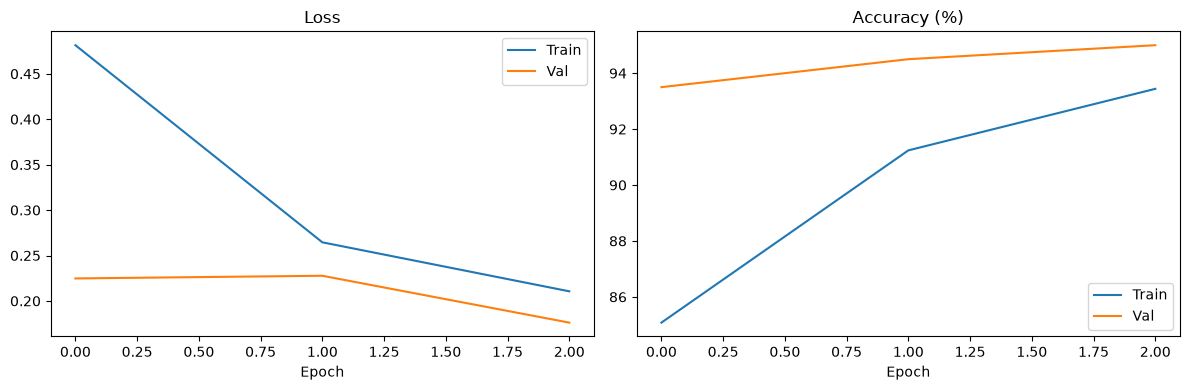

In [8]:
epochs = 3
lr = 0.05
sample_size = 5000  # fresh random subsample each epoch

# x = data, y = label
all_train_x, all_train_y = dataloader("data/mnist/mnist_train.csv")
test_x, test_y = dataloader("data/mnist/mnist_test.csv")

pool_train_x = all_train_x[200:]
pool_train_y = all_train_y[200:]
val_x, val_y = all_train_x[:200], all_train_y[:200]

# kernels are fixed, so the conv features only need computing once
print("Precomputing convolutional features (one-time cost)...")
pool_train_features = prepare_all(pool_train_x)
val_features = prepare_all(val_x)
test_features = prepare_all(test_x)
print("Done.\n")

model = nn(num_inputs=2352, hidden_layer_num=1, hidden_layer_size=64, num_outputs=10)
for l in model.layers[:-1]:
    for n in l.neurons:
        n.activation, n.derivative = ACTIVATIONS['lRelu']

for n in model.layers[-1].neurons:
    n.activation, n.derivative = ACTIVATIONS['linear']

# history tracking for learning curves
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

for epoch in range(epochs):
    indices = np.random.choice(len(pool_train_features), size=sample_size, replace=False)

    epoch_train_features = pool_train_features[indices]
    epoch_train_y = pool_train_y[indices]

    total_loss = 0
    correct = 0
    for i, (nn_input, label) in enumerate(zip(epoch_train_features, epoch_train_y)):
        raw_outputs = model.forward(nn_input)
        predictions = softmax(np.array(raw_outputs)).tolist()

        # store the softmax probabilities as the output neurons' outputs, so backward()
        # computes error = output - target. With softmax + cross-entropy that is exactly
        # dL/dlogits, which is why the output layer uses the 'linear' activation (derivative 1)
        for idx, p in enumerate(predictions):
            model.layers[-1].neurons[idx].output = p

        target = one_hot(label)

        loss = -sum(t * math.log(max(p, EPSILON)) for p, t in zip(predictions, target))
        total_loss += loss

        predicted_digit = predictions.index(max(predictions))
        if predicted_digit == int(label):
            correct += 1

        model.backward(target)
        model.update_weights(learning_rate=lr)

        if (i + 1) % 1000 == 0:
            print(f"Epoch {epoch+1} | Sample {i+1}/{len(epoch_train_features)} | Interm Acc: {correct/(i+1)*100:.1f}%")

    train_acc = (correct / len(epoch_train_features)) * 100
    train_loss = total_loss / len(epoch_train_features)

    val_loss, val_acc = evaluate(model, val_features, val_y)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(f"=== Epoch {epoch+1} Summary ===")
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}%")
    print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.2f}%\n")

# learning curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["train_loss"], label="Train")
axes[0].plot(history["val_loss"], label="Val")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history["train_acc"], label="Train")
axes[1].plot(history["val_acc"], label="Val")
axes[1].set_title("Accuracy (%)")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

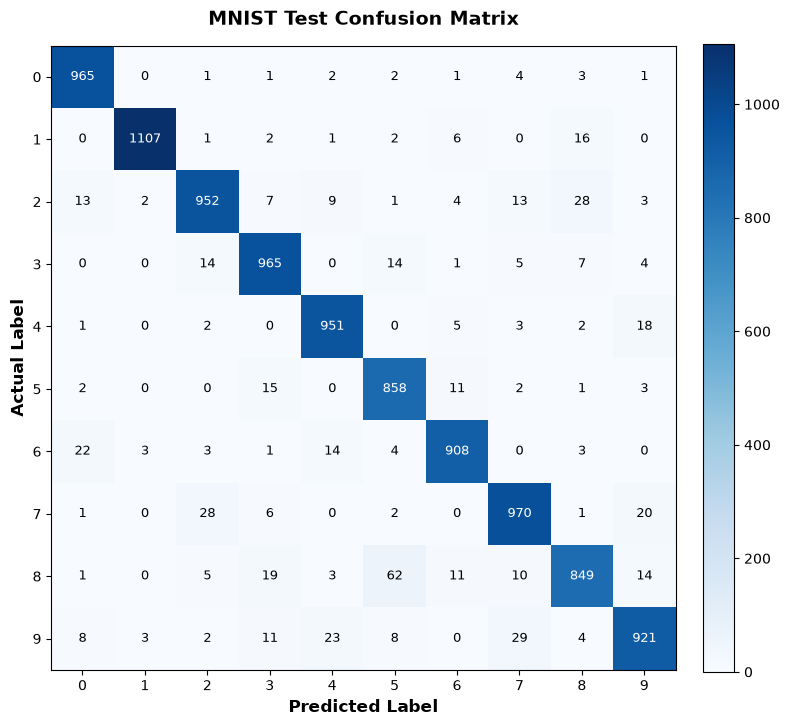

Total Test Samples: 10000
Overall Accuracy:   94.46%
Total Errors:       554
---------------------------------------------
Top 5 Most Frequent Misclassifications:
---------------------------------------------
 1. Actual [8] predicted as [5] -> 62 times (11.2% of all errors)
 2. Actual [9] predicted as [7] -> 29 times (5.2% of all errors)
 3. Actual [2] predicted as [8] -> 28 times (5.1% of all errors)
 4. Actual [7] predicted as [2] -> 28 times (5.1% of all errors)
 5. Actual [9] predicted as [4] -> 23 times (4.2% of all errors)


In [9]:
def evaluate_and_analyze_errors(model, test_features, test_y, num_classes=10, top_k=5):
    cm = np.zeros((num_classes, num_classes), dtype=int)
    
    error_counts = {}
    error_indices = []
    for idx, (nn_input, label) in enumerate(zip(test_features, test_y)):
        actual = int(label)
        raw_outputs = model.forward(nn_input)
        predictions = softmax(np.array(raw_outputs)).tolist()
        pred = predictions.index(max(predictions))
        
        cm[actual, pred] += 1
        
        if actual != pred:
            pair = (actual, pred)
            error_counts[pair] = error_counts.get(pair, 0) + 1
            error_indices.append((idx, actual, pred))

    fig, ax = plt.subplots(figsize=(8, 8))
    im = ax.imshow(cm, cmap='Blues')

    ax.set_xticks(np.arange(num_classes))
    ax.set_yticks(np.arange(num_classes))
    ax.set_xticklabels([str(i) for i in range(num_classes)])
    ax.set_yticklabels([str(i) for i in range(num_classes)])
    
    ax.set_xlabel('Predicted Label', fontsize=12, fontweight='bold')
    ax.set_ylabel('Actual Label', fontsize=12, fontweight='bold')
    ax.set_title('MNIST Test Confusion Matrix', fontsize=14, fontweight='bold', pad=15)

    thresh = cm.max() / 2.0
    for i in range(num_classes):
        for j in range(num_classes):
            val = cm[i, j]
            color = "white" if val > thresh else "black"
            ax.text(j, i, f"{val}", ha="center", va="center", color=color, fontsize=9)

    plt.colorbar(im, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()

    sorted_errors = sorted(error_counts.items(), key=lambda item: item[1], reverse=True)
    total_errors = sum(error_counts.values())
    total_samples = len(test_features)
    accuracy = ((total_samples - total_errors) / total_samples) * 100


    print(f"Total Test Samples: {total_samples}")
    print(f"Overall Accuracy:   {accuracy:.2f}%")
    print(f"Total Errors:       {total_errors}")
    print("-" * 45)
    print(f"Top {min(top_k, len(sorted_errors))} Most Frequent Misclassifications:")
    print("-" * 45)

    for rank, ((actual, pred), count) in enumerate(sorted_errors[:top_k], start=1):
        percentage_of_errors = (count / total_errors) * 100 if total_errors > 0 else 0
        print(f" {rank}. Actual [{actual}] predicted as [{pred}] -> {count} times ({percentage_of_errors:.1f}% of all errors)")

    return error_indices
error_indices = evaluate_and_analyze_errors(model, test_features, test_y)

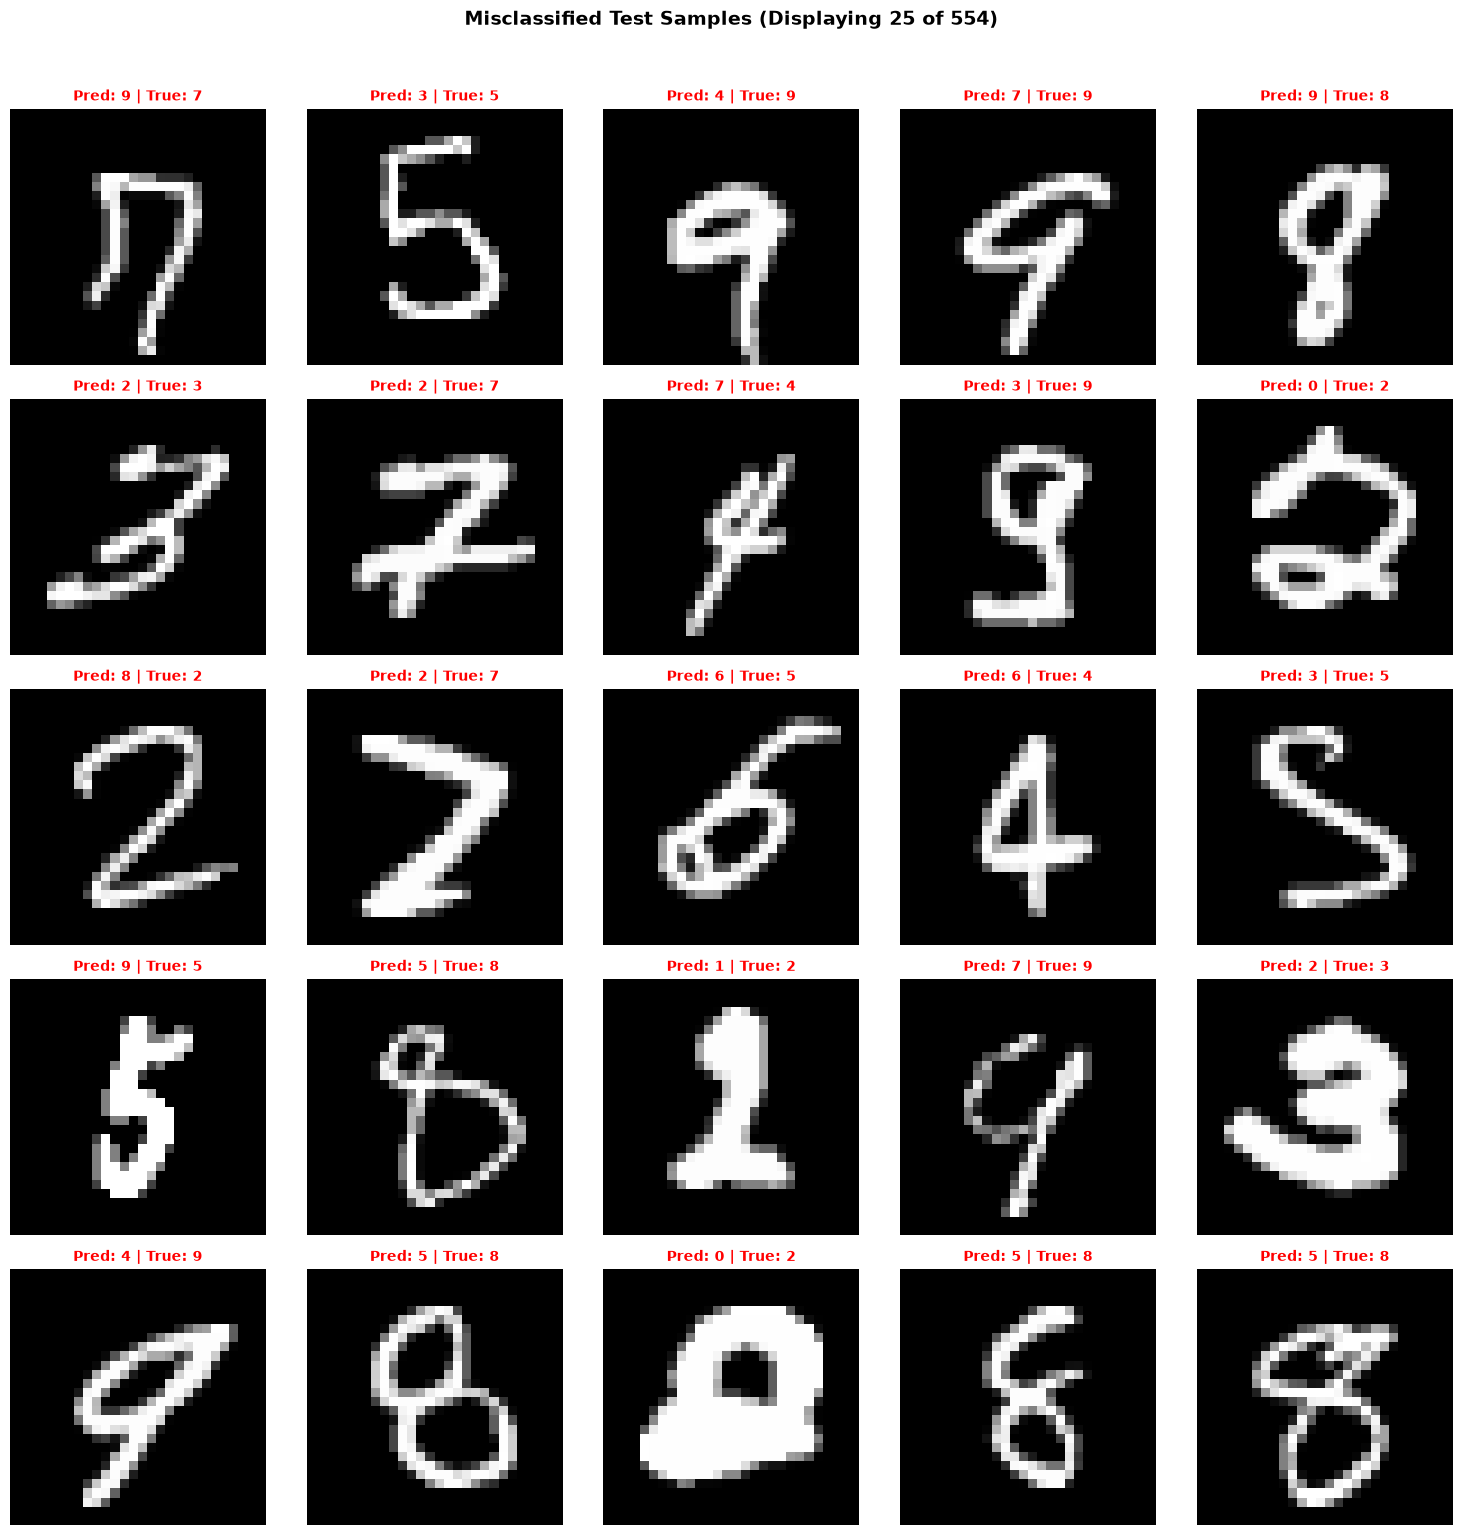

In [10]:
def plot_error_samples(test_x, error_indices, num_samples=25, cols=5, randomize=True):
    display_count = min(num_samples, len(error_indices))
    rows = math.ceil(display_count / cols)
    
    fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3 * rows))
    
    # Flatten axes array for simple indexing
    if display_count == 1:
        axes = np.array([axes])
    axes = axes.flatten()

    # Choose sample indices (random subset or first N errors)
    if randomize and len(error_indices) > display_count:
        sampled_records = [error_indices[i] for i in np.random.choice(len(error_indices), size=display_count, replace=False)]
    else:
        sampled_records = error_indices[:display_count]

    # Render images with red title highlighting misclassifications
    for i, (orig_idx, true_label, pred_label) in enumerate(sampled_records):
        image = test_x[orig_idx]
        axes[i].imshow(image.reshape(28, 28), cmap='gray')
        axes[i].set_title(f"Pred: {pred_label} | True: {true_label}", color='red', fontsize=10, fontweight='bold')
        axes[i].axis('off')

    # Turn off unused subplot axes
    for j in range(display_count, len(axes)):
        axes[j].axis('off')

    plt.suptitle(f"Misclassified Test Samples (Displaying {display_count} of {len(error_indices)})", fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()
plot_error_samples(test_x,error_indices)

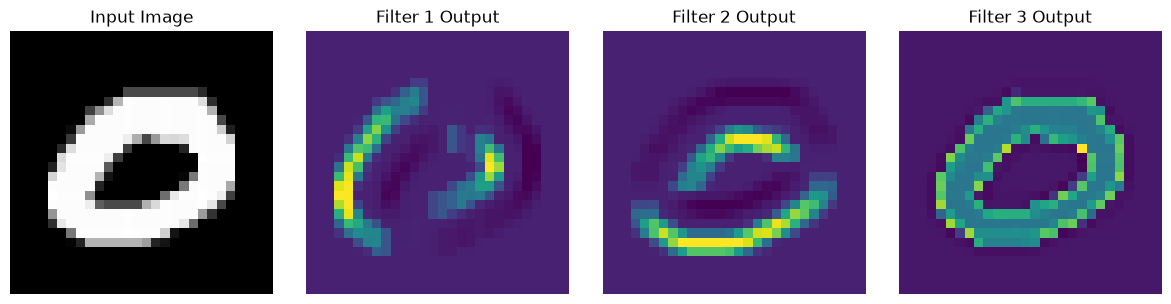

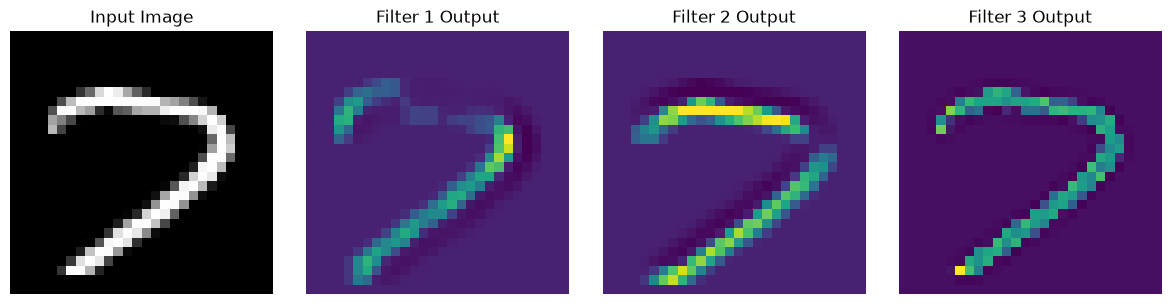

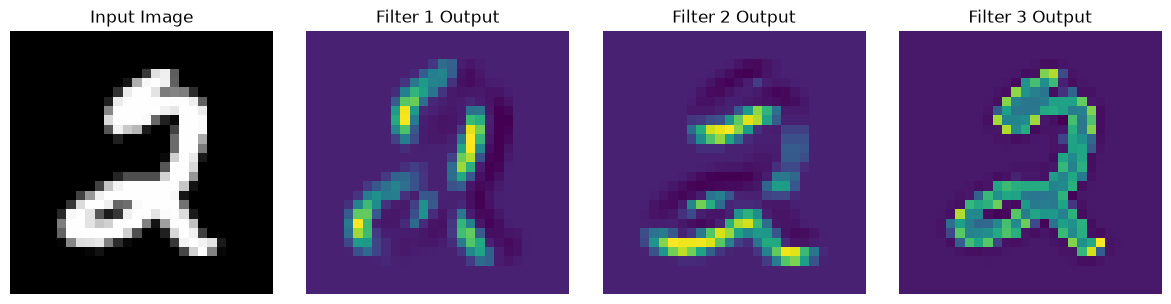

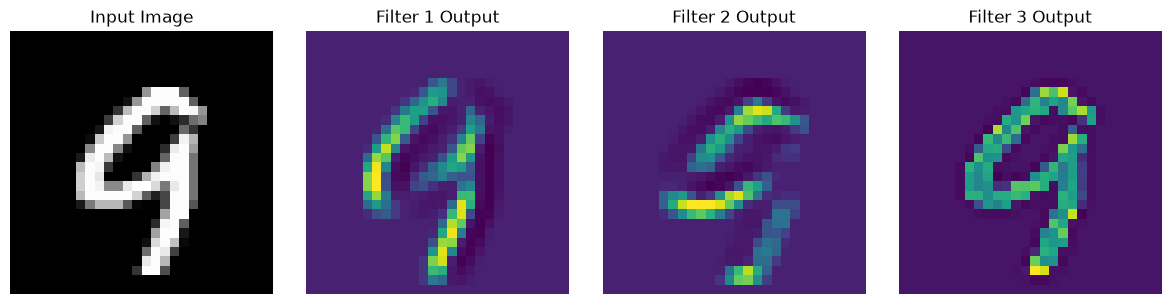

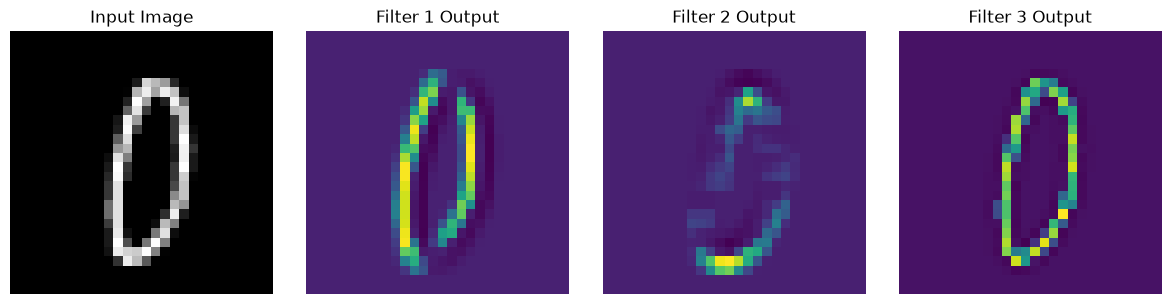

In [11]:
# visualising the predefined kernel activations on inputs
# vertical edge, horizontal edge, sharpening

kernels = [vertical_edge_kernel, horizontal_edge_kernel, sharpening_kernel]

def visualize_conv_features(sample_image, kernels):
    feat_maps = [conv_2d_single(sample_image, k, padding=1) for k in kernels]
    acts = [lRelu(fm) for fm in feat_maps]
    
    num_filters = len(kernels)
    fig, axes = plt.subplots(1, num_filters + 1, figsize=(3 * (num_filters + 1), 3))
    
    axes[0].imshow(sample_image.reshape(28, 28), cmap='gray')
    axes[0].set_title("Input Image")
    axes[0].axis('off')
    
    for idx, act in enumerate(acts):
        axes[idx + 1].imshow(act, cmap='viridis')
        axes[idx + 1].set_title(f"Filter {idx+1} Output")
        axes[idx + 1].axis('off')
        
    plt.tight_layout()
    plt.show()

num_samples = 5
random_indices = np.random.choice(len(test_x), size=min(num_samples, len(test_x)), replace=False)
for i in random_indices: 
    visualize_conv_features(test_x[i], kernels)

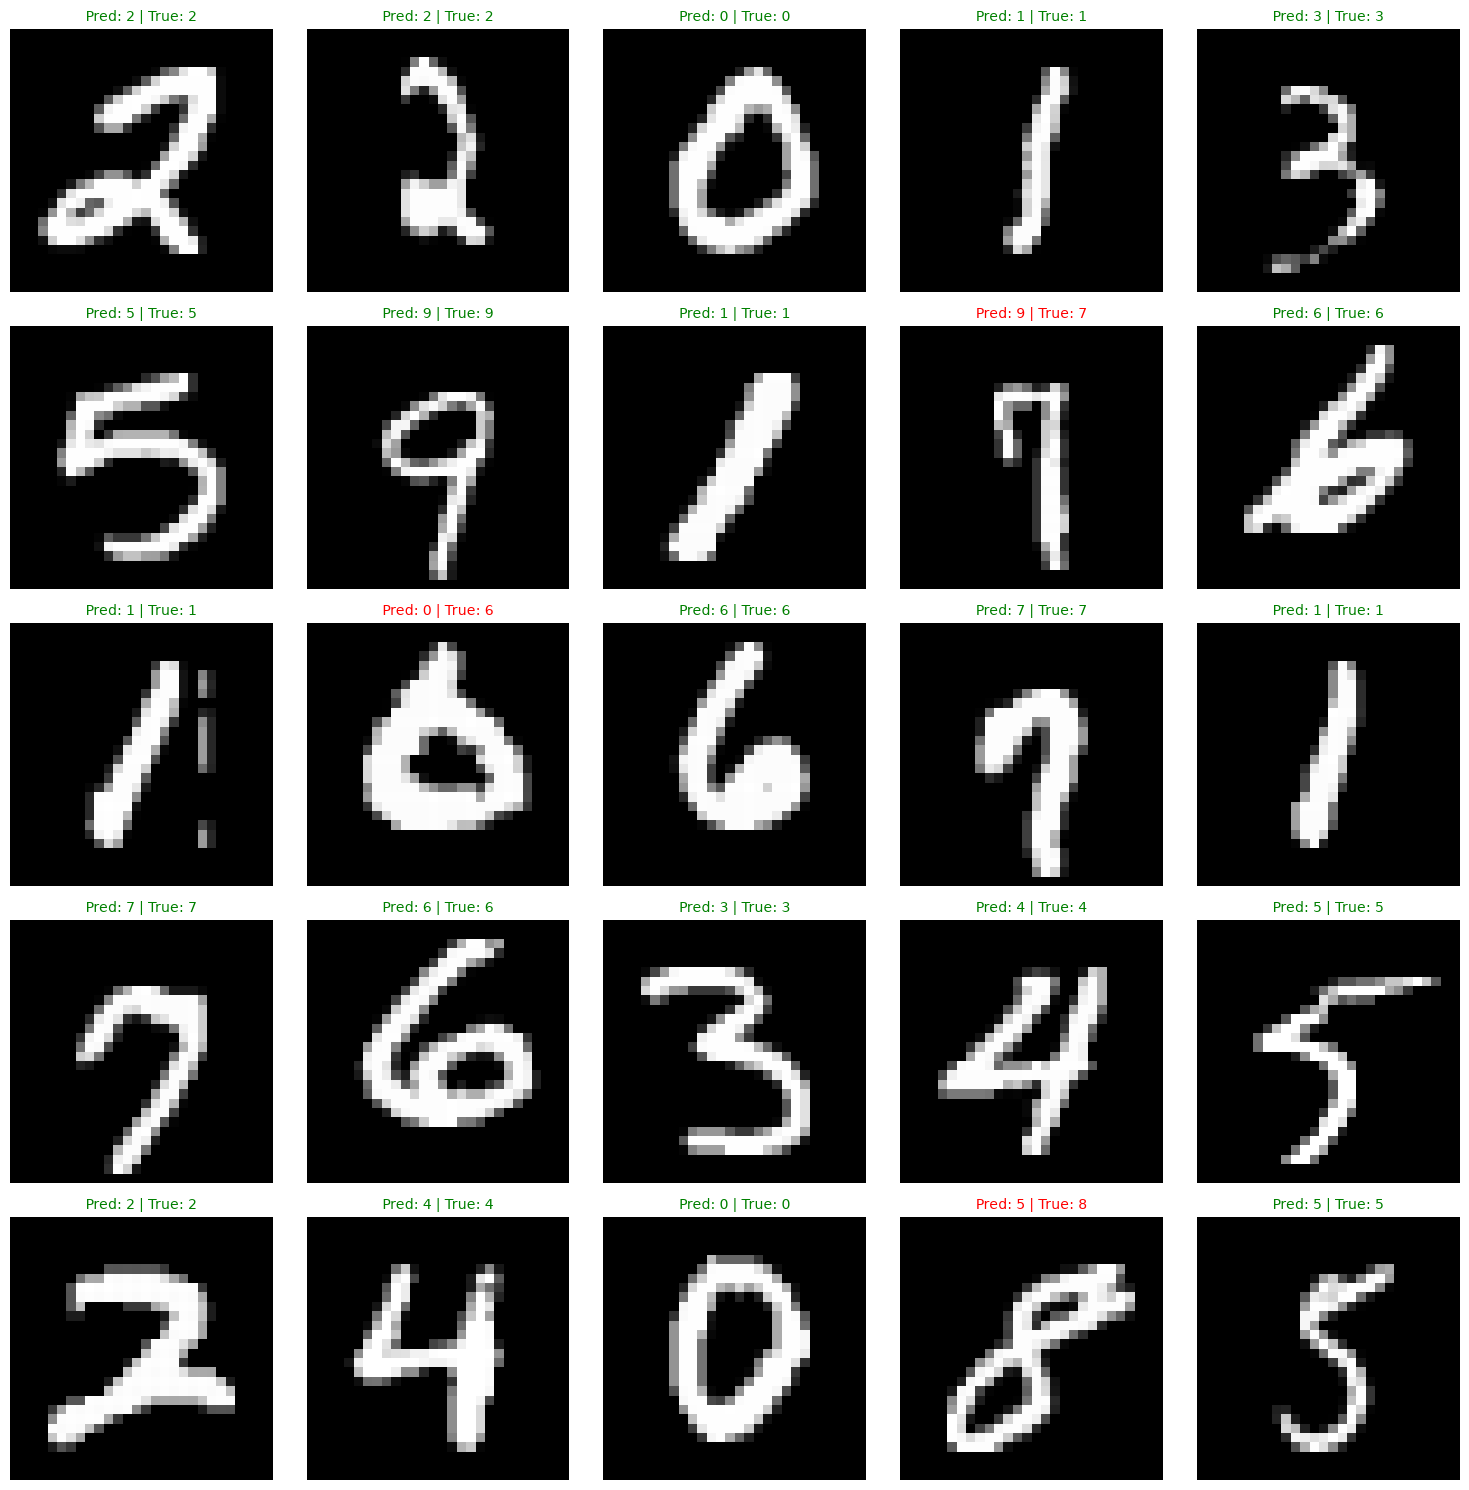

In [12]:
def plot_prediction_samples(model, test_x, test_y, num_samples=20, cols=5, randomize=True):
    rows = math.ceil(num_samples / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3 * rows))
    
    if num_samples > 1:
        axes = axes.flatten()
    else:
        axes = [axes]
    if randomize:
        indices = np.random.choice(len(test_x), size=num_samples, replace=False)
    else:
        indices = np.arange(num_samples)
    
    for i, idx in enumerate(indices):
        image, true_label = test_x[idx], int(test_y[idx])
        
        # same preprocessing as training (fixed kernels, leaky ReLU, / 5.0)
        conv_flat = prepare_input(image)
        preds = model.forward(conv_flat)
        pred_label = preds.index(max(preds))

        axes[i].imshow(image.reshape(28, 28), cmap='gray')
        
        color = 'green' if pred_label == true_label else 'red'
        axes[i].set_title(f"Pred: {pred_label} | True: {true_label}", color=color, fontsize=10)
        axes[i].axis('off')
        
    for j in range(num_samples, len(axes)):
        axes[j].axis('off')
        
    plt.tight_layout()
    plt.show()

plot_prediction_samples(model, test_x, test_y, num_samples=25, cols=5)